# Ranking de Fans UFC · Etapa 2 · Modelo predictivo

**Pregunta:** ¿qué modelo predice mejor quién gana una pelea: **Regresión Logística** o **Random Forest**?

1. Datos
2. Entrenamiento y prueba
3. Los dos modelos
4. Validación cruzada (para elegir)
5. Evaluación en la prueba
6. Matrices de confusión
7. Curva ROC
8. Qué variables pesan
9. Conclusión

In [1]:
from pathlib import Path                                  # para manejar carpetas
import pandas as pd                                       # tablas de datos
import matplotlib.pyplot as plt                           # gráficos
from sklearn.pipeline import Pipeline                     # encadena escalado + modelo
from sklearn.preprocessing import StandardScaler          # escalado de las variables
from sklearn.linear_model import LogisticRegression       # Regresión Logística
from sklearn.ensemble import RandomForestClassifier       # Random Forest
from sklearn.model_selection import TimeSeriesSplit, cross_val_score   # validación cruzada temporal
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, roc_curve)   # métricas

def encontrar_raiz():                                     # busca la carpeta del proyecto
    aqui = Path.cwd().resolve()                           # carpeta desde donde se ejecuta
    for c in [aqui, *aqui.parents, *[p for p in aqui.iterdir() if p.is_dir()]]:   # esta, las de arriba y las de abajo
        if (c / "src" / "modelo.py").exists():            # la raíz es la que tiene src/modelo.py
            return c
    raise FileNotFoundError("No encuentro la carpeta del proyecto.")

PROC = encontrar_raiz() / "data" / "processed"            # carpeta con los datos procesados
AZUL, GRIS, NARANJA = "#2a78d6", "#a3a29c", "#eb6834"     # azul = Regresión Logística · gris = Random Forest
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False,
                     "axes.titleweight": "bold", "axes.titlelocation": "left"})   # gráficos limpios
print("✅ Carpeta del proyecto encontrada")

✅ Carpeta del proyecto encontrada


## 1. Datos

Cada fila es **una pelea** entre A y B. Las variables son **diferencias A − B** con datos **anteriores** a la pelea.
El objetivo `gana_a` vale 1 si ganó A y 0 si ganó B (**clasificación binaria**).

Quién es A y quién es B se **sortea**: en UFCStats el primero de la lista gana el 57%, y el modelo aprendería
"gana el primero". Con el sorteo, cada lado gana cerca del 50%.

In [2]:
VARIABLES = ["dif_elo", "dif_peleas", "dif_pct_victorias", "dif_pct_finish", "dif_racha",
             "dif_ultimas3", "dif_dias_inactivo", "dif_edad", "dif_alcance"]   # las 9 variables

datos = pd.read_csv(PROC / "dataset_modelo.csv", parse_dates=["fecha"])   # una fila por pelea
datos = datos[datos["fecha"] >= "2012-01-01"]             # 2010-2011 son el "calentamiento" del Elo
print(f"{len(datos):,} peleas · gana A el {datos['gana_a'].mean():.0%}")

6,098 peleas · gana A el 50%


## 2. Entrenamiento y prueba

Se separa **por fechas**: el modelo aprende con el pasado y se prueba con peleas que nunca vio, como pasaría en
la realidad. Mezclar al azar dejaría que el modelo "vea el futuro" (fuga de datos).

- **Desde 2012:** en 2010 y 2011 todos tienen casi los mismos puntos Elo (arrancan con 1.500).
- **Entrenamiento 2012–2023** (~80% de las peleas) y **prueba 2024–2026** (~20%, lo más reciente).

In [3]:
entreno = datos[datos["fecha"] < "2024-01-01"]            # el pasado
prueba = datos[datos["fecha"] >= "2024-01-01"]            # el "futuro"
X_tr, y_tr = entreno[VARIABLES], entreno["gana_a"]        # variables y objetivo para entrenar
X_te, y_te = prueba[VARIABLES], prueba["gana_a"]          # variables y objetivo para probar
print(f"Entrenamiento 2012–2023: {len(entreno):,} peleas · Prueba 2024–2026: {len(prueba):,} peleas")

Entrenamiento 2012–2023: 4,806 peleas · Prueba 2024–2026: 1,292 peleas


## 3. Los dos modelos

| Modelo | Cómo funciona | ¿Se puede explicar? |
|---|---|---|
| **Regresión Logística** | Le da un peso a cada variable y calcula una probabilidad | Sí: se ve cuánto pesa cada variable |
| **Random Forest** | 300 árboles de decisión que votan | No: es una caja negra |

In [4]:
modelos = {
    "Regresión Logística": Pipeline([("escalado", StandardScaler()),          # escala las variables
                                     ("modelo", LogisticRegression(max_iter=1000))]),
    "Random Forest": RandomForestClassifier(n_estimators=300, max_depth=6,     # 300 árboles poco profundos
                                            min_samples_leaf=20, random_state=42),
}

## 4. Validación cruzada (para elegir)

Dentro de 2012–2023 se hacen **5 cortes por fecha**: en cada uno se entrena con los años anteriores y se valida con
los siguientes. Con esto se elige el modelo; la prueba 2024–2026 queda para el final.

In [5]:
cv = TimeSeriesSplit(n_splits=5)                          # 5 cortes respetando el orden del tiempo
for nombre, modelo in modelos.items():                    # para cada modelo...
    acc = cross_val_score(modelo, X_tr, y_tr, cv=cv, scoring="accuracy")   # accuracy en cada corte
    print(f"{nombre}: {acc.mean():.1%} (± {acc.std():.1%} entre cortes)")

Regresión Logística: 59.6% (± 3.0% entre cortes)


Random Forest: 59.8% (± 2.5% entre cortes)


**Lectura:** quedan empatados (59,6% y 59,8%). La diferencia es mucho menor que lo que varía de un corte a otro (±3%).

## 5. Evaluación en la prueba 2024–2026

| Métrica | Qué responde |
|---|---|
| **Accuracy** | ¿Qué % de peleas acierta? (las clases están 50/50, así que es justa) |
| **Precision** | Cuando dice "gana A", ¿cuántas veces acierta? |
| **Recall** | De las veces que ganó A, ¿cuántas detectó? |
| **F1** | Equilibrio entre precision y recall |
| **AUC** | ¿Ordena bien quién es más probable que gane? (0,5 = azar) |

Como referencia se agrega una regla sin machine learning: **gana el de más puntos Elo**.

In [6]:
probabilidades = {"Regla: más puntos Elo": 1 / (1 + 10 ** (-X_te["dif_elo"] / 400))}   # fórmula del Elo
for nombre, modelo in modelos.items():                    # para cada modelo...
    modelo.fit(X_tr, y_tr)                                # entrena con todo 2012-2023
    probabilidades[nombre] = modelo.predict_proba(X_te)[:, 1]   # probabilidad de que gane A

filas = []
for nombre, prob in probabilidades.items():
    pred = (prob >= 0.5).astype(int)                      # si A tiene 50% o más, predice "gana A"
    filas.append({"modelo": nombre,
                  "accuracy": accuracy_score(y_te, pred), "precision": precision_score(y_te, pred),
                  "recall": recall_score(y_te, pred), "f1": f1_score(y_te, pred),
                  "auc": roc_auc_score(y_te, prob)})
resultados = pd.DataFrame(filas).set_index("modelo")
resultados.round(3)

,accuracy,precision,recall,f1,auc
modelo,,,,,
Regla: más puntos Elo,0.559,0.560,0.579,0.569,0.585
Regresión Logística,0.618,0.610,0.670,0.638,0.659
Random Forest,0.622,0.608,0.702,0.651,0.661


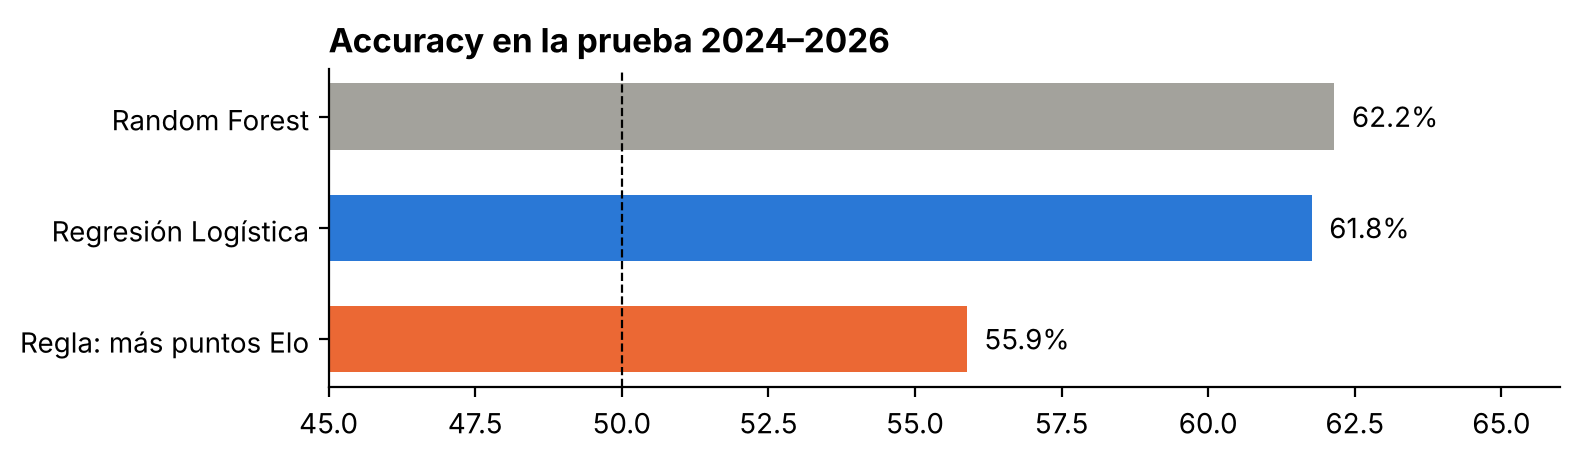

In [7]:
fig, ax = plt.subplots(figsize=(8, 2.4))
orden = resultados["accuracy"].sort_values()              # el mejor queda arriba
colores = [AZUL if "Logística" in m else GRIS if "Forest" in m else NARANJA for m in orden.index]
ax.barh(orden.index, orden * 100, color=colores, height=0.6)
for y, v in enumerate(orden * 100):                       # el valor al final de cada barra
    ax.text(v + 0.3, y, f"{v:.1f}%", va="center")
ax.axvline(50, color="black", ls="--", lw=0.8)            # 50% = tirar una moneda
ax.set_xlim(45, 66)
ax.set_title("Accuracy en la prueba 2024–2026")
plt.tight_layout(); plt.show()

**Lectura:** los dos modelos (61,8% y 62,2%) le ganan a la regla del Elo sola (55,9%). Entre ellos la diferencia es
de 0,4 puntos: unas 5 peleas de 1.292. Las demás métricas también quedan parejas (AUC 0,659 vs. 0,661).

## 6. Matrices de confusión

Filas = lo que pasó; columnas = lo que predijo el modelo.

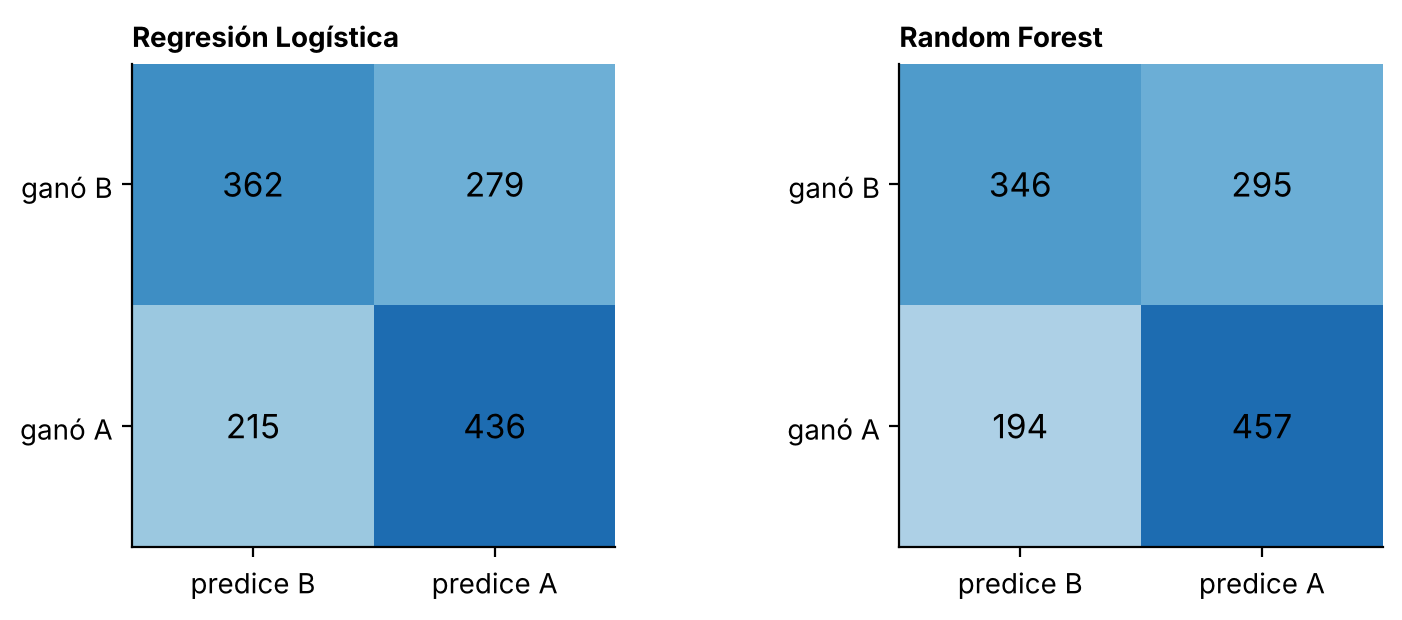

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(8, 3.2))
for ax, nombre in zip(axes, modelos):                     # una matriz por modelo
    m = confusion_matrix(y_te, (probabilidades[nombre] >= 0.5).astype(int))
    ax.imshow(m, cmap="Blues", vmin=0, vmax=m.max() * 1.3)
    for i in range(2):
        for j in range(2):
            ax.text(j, i, m[i, j], ha="center", va="center", fontsize=12)   # cantidad de peleas
    ax.set_xticks([0, 1], ["predice B", "predice A"]); ax.set_yticks([0, 1], ["ganó B", "ganó A"])
    ax.set_title(nombre, fontsize=10)
plt.tight_layout(); plt.show()

**Lectura:** los dos aciertan unas 6 de cada 10 peleas y se equivocan de forma parecida.

## 7. Curva ROC

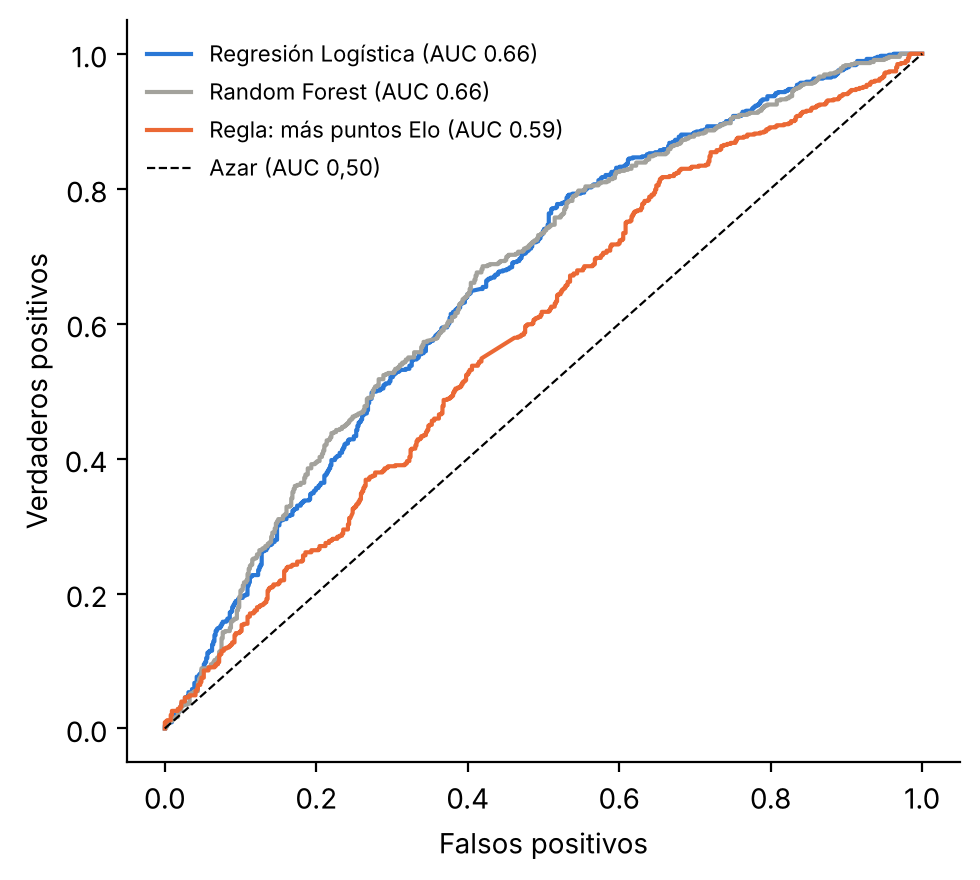

In [9]:
fig, ax = plt.subplots(figsize=(5, 4.5))
for nombre, color in [("Regresión Logística", AZUL), ("Random Forest", GRIS), ("Regla: más puntos Elo", NARANJA)]:
    fpr, tpr, _ = roc_curve(y_te, probabilidades[nombre])   # falsos positivos vs. verdaderos positivos
    ax.plot(fpr, tpr, color=color, label=f"{nombre} (AUC {resultados.loc[nombre, 'auc']:.2f})")
ax.plot([0, 1], [0, 1], "k--", lw=0.8, label="Azar (AUC 0,50)")
ax.set_xlabel("Falsos positivos"); ax.set_ylabel("Verdaderos positivos")
ax.legend(frameon=False, fontsize=8)
plt.tight_layout(); plt.show()

**Lectura:** las curvas de los dos modelos casi se superponen. La regla del Elo sola queda más cerca de la diagonal (azar).

## 8. Qué variables pesan (Regresión Logística)

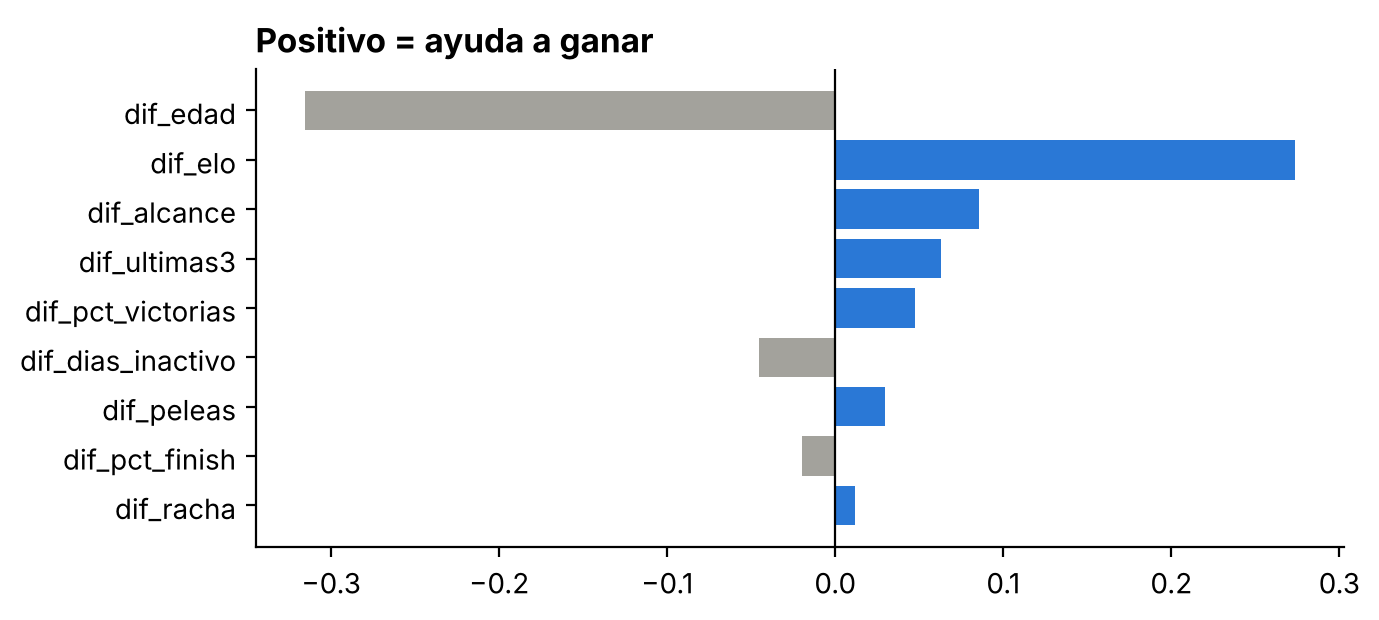

In [10]:
coef = modelos["Regresión Logística"].named_steps["modelo"].coef_[0]   # un peso por variable
pesos = pd.Series(coef, index=VARIABLES).sort_values(key=abs)         # ordenados por tamaño
fig, ax = plt.subplots(figsize=(7, 3.2))
ax.barh(pesos.index, pesos, color=[AZUL if c > 0 else GRIS for c in pesos])   # azul = ayuda a ganar
ax.axvline(0, color="black", lw=0.8)
ax.set_title("Positivo = ayuda a ganar")
plt.tight_layout(); plt.show()

**Lectura:** lo que más pesa es la **edad** (el más joven tiene ventaja) y los **puntos Elo de nuestro ranking**.
O sea, el ranking mide algo real.

## 9. Conclusión

| | Regresión Logística | Random Forest |
|---|---|---|
| Validación cruzada | 59,6% | 59,8% |
| Prueba 2024–2026 | 61,8% | 62,2% |
| AUC | 0,659 | 0,661 |
| ¿Se puede explicar? | **Sí** | No |

**Se elige la Regresión Logística:** rinde prácticamente igual que el Random Forest (la diferencia es de unas pocas
peleas) y se puede explicar variable por variable, que es la idea del proyecto. Además da una probabilidad, que es
lo que muestra la app.

**Límite:** ninguno pasa del ~62%. En la UFC hay muchas sorpresas; el objetivo no es adivinar peleas sino comprobar
que los puntos del ranking sirven para predecir.